# Predição de falhas de máquinas em 24 horas (manutenção preditiva)

## Visão geral do projeto

**Pergunta de negócio:** olhando o histórico recente de uma máquina industrial, ela vai falhar (em qualquer componente) nas **próximas 24 horas**?

**Tipo de problema:** aprendizado **supervisionado**, **classificação binária** (1 = falha em até 24h, 0 = sem falha nesse período).

**Dataset:** *Microsoft Azure Predictive Maintenance* (Kaggle): telemetria horária de 100 máquinas durante 2015, mais tabelas de erros, manutenções, falhas e características das máquinas.

**Dificuldades que o projeto precisa tratar:**
1. **Desbalanceamento forte:** só ~2% das horas antecedem uma falha. Um modelo que sempre diz "não vai falhar" acerta 98% e é inútil. Por isso não usamos acurácia.
2. **Dependência temporal:** os dados são uma linha do tempo. Embaralhar linhas aleatoriamente vazaria informação do futuro para o treino. Toda validação aqui é **cronológica**.
3. **Vazamento de dados (data leakage):** toda feature da hora *t* usa **apenas informações até *t***.

## Etapas do notebook

| # | Etapa | Requisito do trabalho atendido |
|---|---|---|
| 1 | Carga, auditoria e consistência dos dados | Diagnóstico, valores faltantes e inconsistências |
| 2 | Análise exploratória (EDA) | Diagnóstico estatístico |
| 3 | Construção do alvo (target) | Definição do problema |
| 4 | Engenharia de features, codificação e escalonamento | Codificação e escalonamento |
| 5 | Divisão cronológica e validação cruzada temporal | Validação robusta |
| 6 | Métricas e escolha do limiar | Métricas compatíveis (F1, PR-AUC) |
| 7 | Baselines (linhas de base) | Linha de base |
| 8 | Modelos e busca de hiperparâmetros | 2 a 3 algoritmos distintos e otimização |
| 9 | Comparação final dos modelos | Comparação e escolha sem "espiar" o teste |
| 10 | Avaliação detalhada e análise por evento | Interpretação dos resultados |
| 11 | Experimentos de remoção de features (ablação) | Análise crítica |
| 12 | Interpretação do modelo | Análise crítica |
| 13 | Conclusões, limitações e próximos passos | Conclusões |

> **Aviso importante sobre os dados:** a EDA (seção 2) mostra um comportamento muito regular antes das falhas, típico de dados simulados. Isso afeta como os resultados devem ser interpretados. A discussão está nas seções 2, 11 e 13.

In [1]:
# =============================================================================
# IMPORTAÇÕES E CONFIGURAÇÃO
# =============================================================================
import warnings
warnings.filterwarnings("ignore")      # deixa a saída limpa (avisos de versão não afetam o resultado)
import time
from pathlib import Path

import numpy as np                     # operações numéricas
import pandas as pd                    # tabelas (DataFrames)
import matplotlib.pyplot as plt        # gráficos
import seaborn as sns                  # gráficos estatísticos com visual melhor

from sklearn.base import clone                                   # copia um modelo sem os dados treinados
from sklearn.dummy import DummyClassifier                        # modelo "bobo" usado como baseline
from sklearn.linear_model import LogisticRegression              # modelo linear
from sklearn.ensemble import RandomForestClassifier              # ensemble de árvores (bagging)
from sklearn.ensemble import HistGradientBoostingClassifier      # ensemble de árvores (boosting)
from sklearn.model_selection import RandomizedSearchCV           # busca aleatória de hiperparâmetros
from sklearn.preprocessing import StandardScaler                 # escalonamento (média 0, desvio 1)
from sklearn.pipeline import make_pipeline                       # encadeia escalonamento + modelo
from sklearn.inspection import permutation_importance            # importância das variáveis
from sklearn.metrics import (average_precision_score, roc_auc_score, precision_recall_curve,
                             precision_score, recall_score, f1_score, confusion_matrix,
                             ConfusionMatrixDisplay)

sns.set_theme(style="whitegrid")

# ---------------------------- PARÂMETROS DO PROJETO ----------------------------
DATA_DIR = Path("data")                  # pasta onde estão os 5 CSVs
HORIZON_H = 24                           # horizonte de predição: "falha nas próximas 24 horas"
RANDOM_STATE = 42                        # semente: garante que os resultados sejam reproduzíveis
TEST_START = pd.Timestamp("2015-10-01")  # tudo a partir desta data é o conjunto de TESTE (final, intocado)

# Datas que delimitam os 3 "folds" da validação cruzada temporal (meses de jul, ago e set).
# Em cada fold, o modelo treina com TUDO que veio antes do mês e é avaliado nesse mês.
CV_BOUNDARIES = pd.to_datetime(["2015-07-01", "2015-08-01", "2015-09-01", "2015-10-01"])

# Custo relativo dos erros, usado para escolher um limiar "orientado a negócio":
#   falso negativo = falha que não foi avisada (máquina para, caro)
#   falso positivo = alarme falso (inspeção desnecessária, barato)
COST_FN, COST_FP = 10, 1

SENSORS = ["volt", "rotate", "pressure", "vibration"]   # colunas de telemetria
COMPS = ["comp1", "comp2", "comp3", "comp4"]            # componentes das máquinas
MAX_H = 24 * 365                         # valor usado para "horas desde a última manutenção/falha" quando nunca houve

# ------------------------------ TEMPO DE EXECUÇÃO ------------------------------
# A busca de hiperparâmetros é a parte mais demorada. Se o seu computador estiver lento,
# troque MODO_RAPIDO para True (usa menos árvores e menos combinações; o resultado fica ligeiramente
# menos otimizado, mas a conclusão do trabalho não muda).
MODO_RAPIDO = False
if MODO_RAPIDO:
    N_ITER = {"LogReg": 3, "RandomForest": 3, "HistGB": 3}   # nº de combinações testadas por modelo
    RF_TREES, HGB_ITER = 60, 100
else:
    N_ITER = {"LogReg": 5, "RandomForest": 6, "HistGB": 8}
    RF_TREES, HGB_ITER = 200, 300

## 1. Carga, auditoria e consistência dos dados

**O que fazemos:** carregamos as 5 tabelas e conferimos se estão íntegras antes de qualquer modelagem.

**Por quê:** erros nos dados (nulos, duplicatas, IDs inexistentes, buracos na série temporal) contaminam tudo o que vem depois. As features em janela (médias de 24h etc.) assumem que a telemetria é **horária e sem buracos**, então precisamos confirmar isso.

| Tabela | Conteúdo |
|---|---|
| `telemetry` | uma linha por máquina por hora: tensão (`volt`), rotação (`rotate`), pressão (`pressure`), vibração (`vibration`) |
| `errors` | erros registrados (`error1` a `error5`), com data/hora |
| `maint` | trocas/manutenções de componentes (`comp1` a `comp4`) |
| `failures` | falhas ocorridas (data/hora, máquina e componente que falhou) |
| `machines` | modelo (`model1` a `model4`) e idade de cada máquina |

In [2]:
# Leitura dos CSVs. parse_dates converte a coluna "datetime" de texto para data/hora de verdade,
# o que permite fazer contas com tempo (diferenças em horas, ordenação cronológica etc.).
telemetry = pd.read_csv(DATA_DIR / "PdM_telemetry.csv", parse_dates=["datetime"])
errors    = pd.read_csv(DATA_DIR / "PdM_errors.csv",    parse_dates=["datetime"])
maint     = pd.read_csv(DATA_DIR / "PdM_maint.csv",     parse_dates=["datetime"])
failures  = pd.read_csv(DATA_DIR / "PdM_failures.csv",  parse_dates=["datetime"])
machines  = pd.read_csv(DATA_DIR / "PdM_machines.csv")

# --- Diagnóstico geral: tamanho, valores faltantes e linhas duplicadas de cada tabela ---
tables = {"telemetry": telemetry, "errors": errors, "maint": maint,
          "failures": failures, "machines": machines}
for name, d in tables.items():
    print(f"{name:10s} shape={str(d.shape):14s} nulos={int(d.isna().sum().sum()):3d}  duplicatas={int(d.duplicated().sum())}")

print("\nPeríodo da telemetria:", telemetry.datetime.min(), "->", telemetry.datetime.max())
print("Máquinas:", telemetry.machineID.nunique())

# --- Regularidade temporal: a diferença entre leituras consecutivas de cada máquina deve ser sempre 1 hora.
# Se houvesse buracos, as janelas móveis (ex.: "últimas 24 leituras") não corresponderiam a 24 horas reais.
gaps = (telemetry.sort_values(["machineID", "datetime"])
                 .groupby("machineID")["datetime"].diff().dropna())
print("\nIntervalos entre leituras:\n", gaps.value_counts().head())

# --- Quantidade de falhas: define se o problema é viável. Poucas falhas = modelo instável.
print("\nFalhas por componente:\n", failures.failure.value_counts())
per_machine = failures.groupby("machineID").size()
print("\nFalhas por máquina:\n", per_machine.describe().round(2))
print("Máquinas sem nenhuma falha:", machines.machineID.nunique() - per_machine.shape[0])

telemetry  shape=(876100, 6)    nulos=  0  duplicatas=0
errors     shape=(3919, 3)      nulos=  0  duplicatas=0
maint      shape=(3286, 3)      nulos=  0  duplicatas=0
failures   shape=(761, 3)       nulos=  0  duplicatas=0
machines   shape=(100, 3)       nulos=  0  duplicatas=0

Período da telemetria: 2015-01-01 06:00:00 -> 2016-01-01 06:00:00
Máquinas: 100

Intervalos entre leituras:
 datetime
0 days 01:00:00    876000
Name: count, dtype: int64

Falhas por componente:
 failure
comp2    259
comp1    192
comp4    179
comp3    131
Name: count, dtype: int64

Falhas por máquina:
 count    98.00
mean      7.77
std       3.46
min       2.00
25%       5.00
50%       7.00
75%      10.00
max      19.00
dtype: float64
Máquinas sem nenhuma falha: 2


In [3]:
# --- Checagens de CONSISTÊNCIA (inconsistências nos dados) ---

# 1) Integridade referencial: todo machineID das tabelas deve existir na tabela "machines".
ids_maq = set(machines.machineID)
for nome, tab in [("telemetry", telemetry), ("errors", errors), ("maint", maint), ("failures", failures)]:
    fora = set(tab.machineID) - ids_maq
    print(f"{nome:10s}: IDs de máquina que não existem em 'machines' = {len(fora)}")

# 2) Eventos fora do período da telemetria. Erros e falhas só fazem sentido dentro da janela observada.
#    (A tabela de manutenção pode ter datas de 2014: isso é esperado, e é útil para saber a última manutenção.)
ini, fim = telemetry.datetime.min(), telemetry.datetime.max()
print("\nErros fora do período da telemetria  :", int(((errors.datetime < ini) | (errors.datetime > fim)).sum()))
print("Falhas fora do período da telemetria :", int(((failures.datetime < ini) | (failures.datetime > fim)).sum()))
print("Manutenções anteriores ao início da telemetria:", int((maint.datetime < ini).sum()))

# 3) Valores fisicamente impossíveis (sensores não deveriam ser zero ou negativos).
print("\nLeituras <= 0 por sensor:\n", (telemetry[SENSORS] <= 0).sum())

# 4) Outliers pelo critério do IQR (valores muito distantes da faixa central).
#    DECISÃO: NÃO removemos outliers. Em manutenção preditiva, valores extremos podem ser
#    justamente o sinal de que uma falha está chegando; removê-los destruiria a informação que queremos aprender.
print("\nProporção de outliers (IQR) por sensor:")
for s in SENSORS:
    q1, q3 = telemetry[s].quantile([0.25, 0.75])
    iqr = q3 - q1
    frac = ((telemetry[s] < q1 - 1.5 * iqr) | (telemetry[s] > q3 + 1.5 * iqr)).mean()
    print(f"  {s:10s}: {frac:.2%}")

telemetry : IDs de máquina que não existem em 'machines' = 0
errors    : IDs de máquina que não existem em 'machines' = 0
maint     : IDs de máquina que não existem em 'machines' = 0
failures  : IDs de máquina que não existem em 'machines' = 0

Erros fora do período da telemetria  : 0
Falhas fora do período da telemetria : 0
Manutenções anteriores ao início da telemetria: 400

Leituras <= 0 por sensor:
 volt         0
rotate       0
pressure     0
vibration    0
dtype: int64

Proporção de outliers (IQR) por sensor:
  volt      : 0.85%
  rotate    : 0.98%
  pressure  : 1.78%
  vibration : 1.27%


**Como ler (para a apresentação):**
- Se não há nulos, duplicatas, IDs inexistentes nem buracos na série, **não é necessário imputar nem corrigir nada**. Os dados chegam limpos.
- O número de falhas (centenas, espalhadas por quase todas as máquinas) é suficiente para treinar e validar um modelo.
- Outliers foram **mantidos de propósito**, por serem possível sinal de falha.

## 2. Análise exploratória (EDA)

**Objetivo:** entender o comportamento dos sensores, onde as falhas acontecem e, principalmente, **se existe sinal nos dados antes de uma falha**. Sem sinal, nenhum modelo funciona.

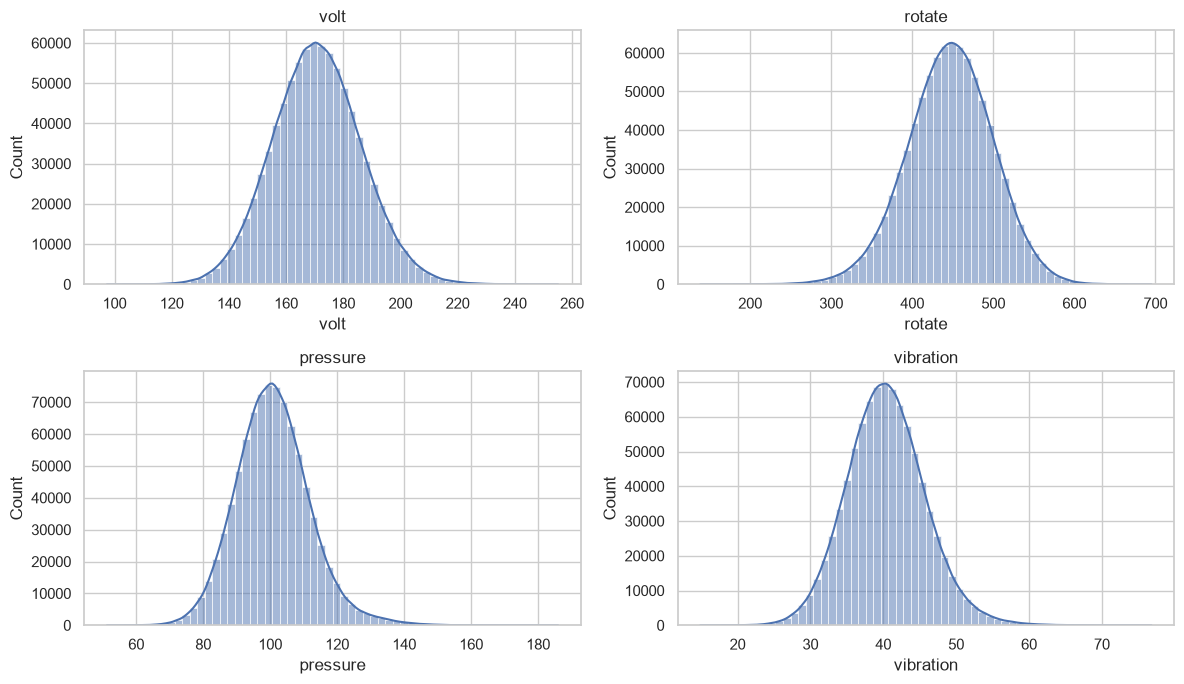

            volt     rotate   pressure  vibration
count  876100.00  876100.00  876100.00  876100.00
mean      170.78     446.61     100.86      40.39
std        15.51      52.67      11.05       5.37
min        97.33     138.43      51.24      14.88
25%       160.30     412.31      93.50      36.78
50%       170.61     447.56     100.43      40.24
75%       181.00     482.18     107.56      43.78
max       255.12     695.02     185.95      76.79


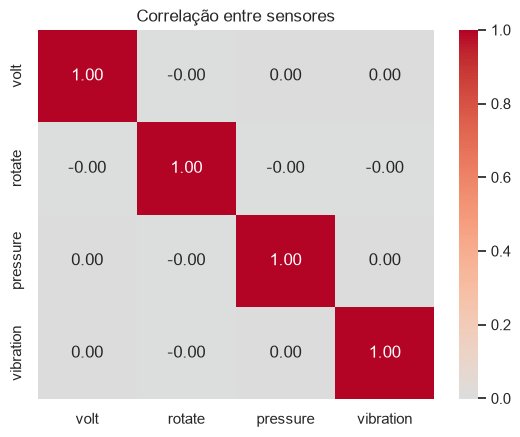

In [4]:
# Distribuição de cada sensor (histograma + curva suave).
# Formato de sino = comportamento "normal" e estável; caudas longas = valores raros/extremos.
fig, axes = plt.subplots(2, 2, figsize=(12, 7))
for ax, s in zip(axes.ravel(), SENSORS):
    sns.histplot(telemetry[s], bins=60, kde=True, ax=ax)
    ax.set_title(s)
plt.tight_layout(); plt.show()

print(telemetry[SENSORS].describe().round(2))      # resumo estatístico: média, desvio, quartis, mín e máx

# Correlação entre sensores: valores próximos de 1 ou -1 indicariam variáveis redundantes.
# Aqui esperamos correlações baixas, ou seja, cada sensor traz informação própria.
sns.heatmap(telemetry[SENSORS].corr(), annot=True, cmap="coolwarm", center=0, fmt=".2f")
plt.title("Correlação entre sensores"); plt.show()

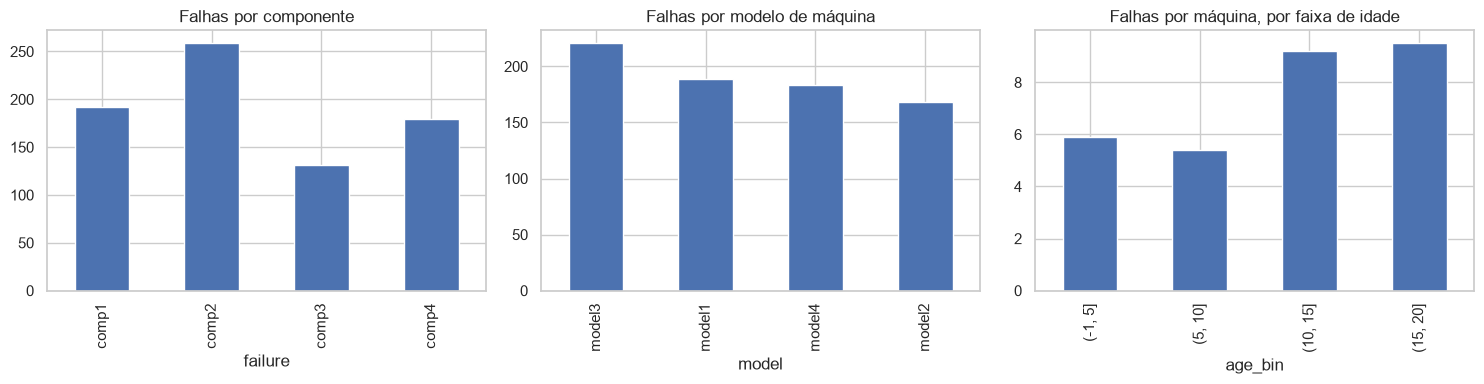

In [5]:
# Onde as falhas se concentram? Três cortes: por componente, por modelo de máquina e por idade.
fail_m = failures.merge(machines, on="machineID")        # junta cada falha com o modelo/idade da máquina
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

failures.failure.value_counts().sort_index().plot.bar(ax=axes[0], title="Falhas por componente")
fail_m.model.value_counts().plot.bar(ax=axes[1], title="Falhas por modelo de máquina")

# Faixas de idade. Dividimos pelo nº de máquinas em cada faixa para a comparação ser justa
# (uma faixa com mais máquinas teria mais falhas só por ter mais máquinas).
machines["age_bin"] = pd.cut(machines.age, bins=[-1, 5, 10, 15, 20, 100])
fail_m["age_bin"] = pd.cut(fail_m.age, bins=machines["age_bin"].cat.categories)
rate = fail_m.groupby("age_bin").size() / machines.groupby("age_bin").size()
rate.plot.bar(ax=axes[2], title="Falhas por máquina, por faixa de idade")
plt.tight_layout(); plt.show()

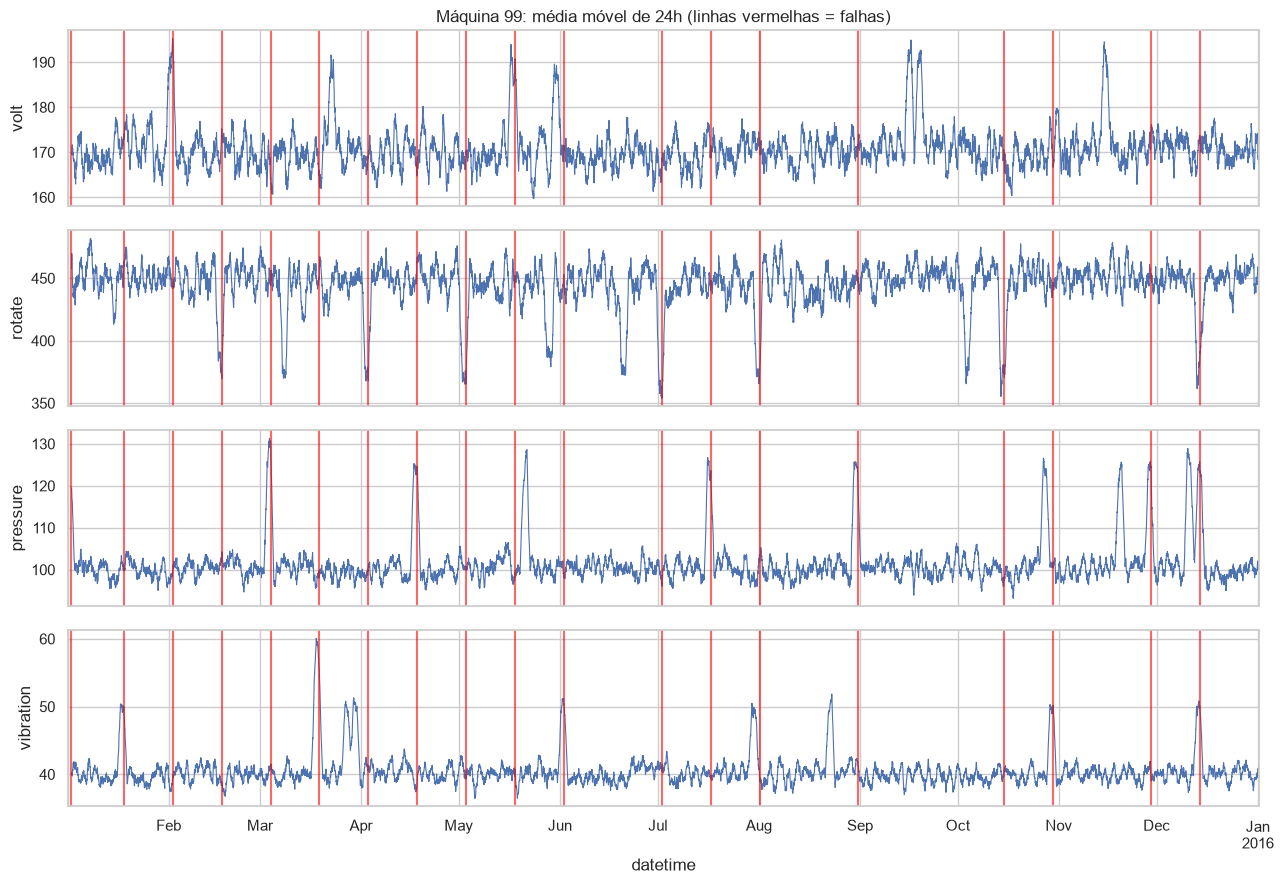

In [6]:
# Visão de UMA máquina ao longo do ano (a que mais falhou), com as falhas marcadas por linhas vermelhas.
# Usamos média móvel de 24h para suavizar o ruído e ver a tendência.
m = failures.machineID.value_counts().idxmax()
sub = telemetry[telemetry.machineID == m].set_index("datetime")
fig, axes = plt.subplots(4, 1, figsize=(13, 9), sharex=True)
for ax, s in zip(axes, SENSORS):
    sub[s].rolling(24).mean().plot(ax=ax, lw=0.8)
    ax.set_ylabel(s)
    for d in failures.loc[failures.machineID == m, "datetime"]:
        ax.axvline(d, color="red", alpha=0.6)
axes[0].set_title(f"Máquina {m}: média móvel de 24h (linhas vermelhas = falhas)")
plt.tight_layout(); plt.show()

### Comportamento dos sensores antes da falha (estudo de evento)

**O que o gráfico abaixo mostra:** para cada falha, olhamos as 72 horas anteriores. Padronizamos cada sensor **por máquina** (z-score: quantos desvios-padrão acima ou abaixo da média daquela máquina), para que máquinas diferentes sejam comparáveis. Depois fazemos a média sobre todas as falhas. O eixo horizontal é "horas antes da falha" (0 = momento da falha).

**Como interpretar:** se as curvas ficam em torno de 0 e se afastam perto da falha, há sinal aproveitável.

**O que se observa e por que importa:** os sensores mudam **de uma só vez, de forma abrupta, cerca de 48 horas antes da falha**, e ficam num patamar constante até o fim. Máquinas reais degradam de forma gradual e ruidosa. Um degrau tão limpo é característico de **dados simulados**, em que o gerador injeta um padrão anômalo nas 48h anteriores à falha. Isso explica por que os modelos terão desempenho muito alto, e deve ser dito na apresentação como **limitação**.

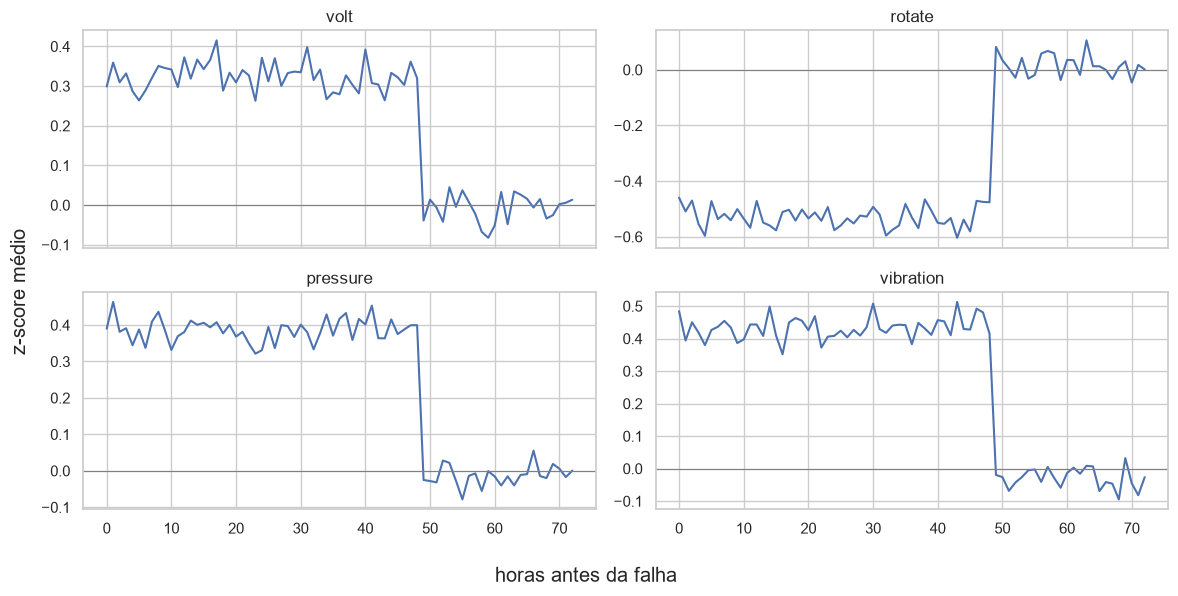

In [7]:
# Padroniza cada sensor por máquina (z-score): (valor - média da máquina) / desvio da máquina.
tz = telemetry.copy()
for s in SENSORS:
    tz[s] = tz.groupby("machineID")[s].transform(lambda x: (x - x.mean()) / x.std())
by_m = {k: g.set_index("datetime").sort_index() for k, g in tz.groupby("machineID")}

# Para cada falha, recorta as 72h anteriores e guarda "quantas horas faltam para a falha" (h_before).
rows = []
for _, f in failures.drop_duplicates(["machineID", "datetime"]).iterrows():
    g = by_m[f.machineID]
    w = g.loc[f.datetime - pd.Timedelta(hours=72): f.datetime, SENSORS].copy()
    w["h_before"] = ((f.datetime - w.index) / pd.Timedelta(hours=1)).astype(int)
    rows.append(w)
event = pd.concat(rows).groupby("h_before")[SENSORS].mean()   # média sobre todas as falhas

fig, axes = plt.subplots(2, 2, figsize=(12, 6), sharex=True)
for ax, s in zip(axes.ravel(), SENSORS):
    ax.plot(event.index, event[s]); ax.axhline(0, color="gray", lw=0.8)
    ax.set_title(s); ax.invert_xaxis()                      # inverte para o tempo "correr" da esquerda p/ a direita
fig.supxlabel("horas antes da falha"); fig.supylabel("z-score médio")
plt.tight_layout(); plt.show()

## 3. Construção do alvo (target)

**Definição:** para cada máquina e cada hora *t*, `target = 1` se existir uma falha (em **qualquer** componente) no intervalo `(t, t + 24h]`; caso contrário, `0`.

**Detalhes que importam:**
- A falha precisa ser **estritamente depois** de *t*. Se a falha ocorre exatamente em *t*, ela já aconteceu e não há o que prever.
- Na prática, as ~24 linhas horárias anteriores a cada falha viram positivas.
- Usamos `merge_asof` (junção por proximidade de tempo) com `direction="forward"` para achar, de forma eficiente, a **próxima** falha de cada máquina depois de cada hora.

In [8]:
def build_target(tele, failures, horizon_h):
    """Marca 1 se a próxima falha da máquina ocorre em (t, t + horizon_h]."""
    left = tele.sort_values("datetime")                      # merge_asof exige ordenação pela chave de tempo
    nxt = failures[["machineID", "datetime"]].drop_duplicates().copy()
    nxt["next_failure"] = nxt["datetime"]                    # guarda a data da falha numa coluna própria
    nxt = nxt.sort_values("datetime")
    # Para cada linha da telemetria, procura (na mesma máquina, by="machineID") a PRIMEIRA falha
    # que acontece depois dela (direction="forward"). allow_exact_matches=False => estritamente depois.
    out = pd.merge_asof(left, nxt, on="datetime", by="machineID",
                        direction="forward", allow_exact_matches=False)
    # Se a próxima falha está a no máximo 24h de distância, o alvo é 1. Sem próxima falha (NaT), o resultado é False => 0.
    out["target"] = ((out["next_failure"] - out["datetime"]) <= pd.Timedelta(hours=horizon_h)).astype(int)
    return out.drop(columns="next_failure")

df = build_target(telemetry, failures, HORIZON_H)
df = df.sort_values(["machineID", "datetime"]).reset_index(drop=True)   # ordem: máquina e depois tempo (necessário p/ janelas móveis)

print("Linhas:", len(df))
print("Linhas positivas:", int(df.target.sum()), f"({df.target.mean():.2%})")   # ~2%: problema desbalanceado

Linhas: 876100
Linhas positivas: 17184 (1.96%)


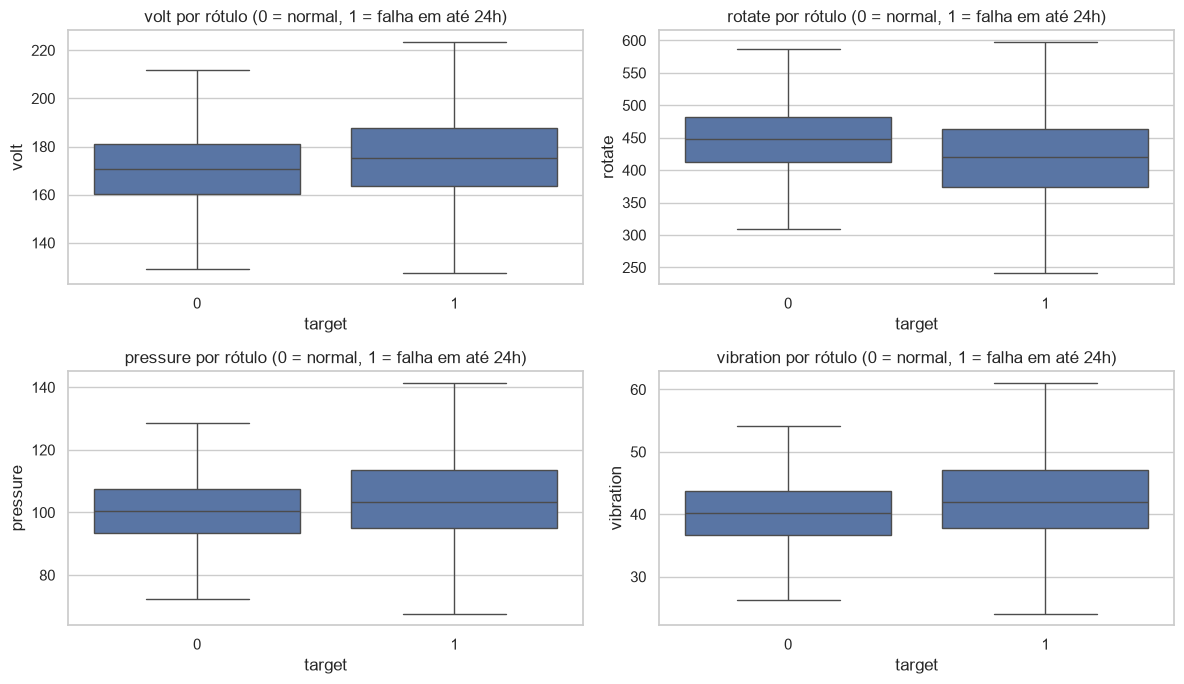

In [9]:
# Os sensores já parecem diferentes entre as classes? Boxplots (sem os pontos extremos para facilitar a leitura).
fig, axes = plt.subplots(2, 2, figsize=(12, 7))
for ax, s in zip(axes.ravel(), SENSORS):
    sns.boxplot(data=df, x="target", y=s, ax=ax, showfliers=False)
    ax.set_title(f"{s} por rótulo (0 = normal, 1 = falha em até 24h)")
plt.tight_layout(); plt.show()

## 4. Engenharia de features, codificação e escalonamento

**Ideia central:** o modelo decide sobre a hora *t* usando **resumos do passado recente**, não apenas a leitura isolada daquela hora. Uma única leitura é ruidosa; a média das últimas 24h mostra a tendência.

**Regra de ouro (evitar vazamento):** toda feature em *t* usa somente dados até *t*. Nenhuma olha para o futuro.

| Grupo | Features | Intuição |
|---|---|---|
| Sensores | valor atual; média e desvio em 3h, 12h e 24h; mín e máx em 24h; tendência (média 3h − média 24h) | níveis, instabilidade e direção recente |
| Erros | contagem de cada `errorN` e total, nas últimas 24h e 72h | muitos erros recentes sugerem problema |
| Manutenção | horas desde a última troca de cada componente | componentes antigos tendem a falhar mais |
| Falhas | horas desde a última falha da máquina | falhas costumam se agrupar |
| Metadados | modelo da máquina (one-hot) e idade | perfil da máquina |

**Tratamento de faltantes:** as primeiras 23h de cada máquina não têm janela de 24h completa; essas linhas são removidas. Quando uma máquina nunca teve manutenção/falha, usamos um valor alto fixo (`MAX_H`, 1 ano), significando "faz muito tempo".

**Codificação:** `model` é categórica, então usamos *one-hot* (uma coluna 0/1 por modelo). **Escalonamento:** é aplicado apenas à Regressão Logística, dentro do pipeline do modelo (seção 8), porque ela é sensível à escala das variáveis. As árvores não precisam disso.

In [10]:
def add_sensor_features(d):
    """Estatísticas móveis dos sensores, calculadas SEPARADAMENTE para cada máquina (groupby)."""
    g = d.groupby("machineID")
    new = {}
    for s in SENSORS:
        for w in (3, 12, 24):                                  # janelas de 3, 12 e 24 horas
            # min_periods=w: só calcula quando já existem w leituras (evita médias com pouca informação).
            r = g[s].rolling(w, min_periods=w)
            new[f"{s}_mean_{w}h"] = r.mean().reset_index(level=0, drop=True)   # nível médio
            new[f"{s}_std_{w}h"]  = r.std().reset_index(level=0, drop=True)    # instabilidade (variação)
        r24 = g[s].rolling(24, min_periods=24)
        new[f"{s}_min_24h"] = r24.min().reset_index(level=0, drop=True)
        new[f"{s}_max_24h"] = r24.max().reset_index(level=0, drop=True)
        # Tendência: se a média das últimas 3h está acima da média de 24h, o sensor está subindo.
        new[f"{s}_trend"]   = new[f"{s}_mean_3h"] - new[f"{s}_mean_24h"]
    return pd.concat([d, pd.DataFrame(new, index=d.index)], axis=1)


def add_error_features(d, errors):
    """Contagem de erros recentes por máquina (soma móvel em 24h e 72h), por tipo de erro e total."""
    e = errors.copy()
    e["datetime"] = e["datetime"].dt.floor("h")                # alinha o erro à hora cheia da telemetria
    # Tabela: uma linha por (máquina, hora) e uma coluna por tipo de erro com a contagem naquela hora.
    cnt = (e.groupby(["machineID", "datetime", "errorID"]).size()
             .unstack("errorID", fill_value=0))
    cnt = cnt.reindex(columns=sorted(errors.errorID.unique()), fill_value=0).reset_index()
    d = d.merge(cnt, on=["machineID", "datetime"], how="left")  # how="left" mantém todas as linhas da telemetria
    err_cols = [c for c in cnt.columns if c.startswith("error")]
    d[err_cols] = d[err_cols].fillna(0)                        # hora sem erro = 0 erros (não é dado faltante)
    d["err_total"] = d[err_cols].sum(axis=1)
    g = d.groupby("machineID")
    new = {}
    for c in err_cols + ["err_total"]:
        for w in (24, 72):                                     # soma dos erros nas últimas 24h e 72h
            new[f"{c}_sum_{w}h"] = g[c].rolling(w, min_periods=1).sum().reset_index(level=0, drop=True)
    d = d.drop(columns=err_cols + ["err_total"])               # remove as contagens "da hora"; ficam só as janelas
    return pd.concat([d, pd.DataFrame(new, index=d.index)], axis=1)


def add_event_recency(d, events, label, comps=None):
    """Horas desde o último evento (manutenção ou falha) até t, usando só eventos com datetime <= t."""
    d = d.sort_values("datetime")
    groups = {"": events} if comps is None else {c: events[events.iloc[:, -1] == c] for c in comps}
    for key, ev in groups.items():
        ev = ev[["machineID", "datetime"]].drop_duplicates().copy()
        ev["last_ev"] = ev["datetime"]
        ev = ev.sort_values("datetime")
        # direction="backward": para cada hora t, pega o evento mais recente ANTES (ou em) t. Nunca olha o futuro.
        d = pd.merge_asof(d, ev, on="datetime", by="machineID", direction="backward")
        name = f"h_since_{label}" + (f"_{key}" if key else "")
        # Se nunca houve evento (NaN), assume "muito tempo" (MAX_H); limita valores a MAX_H.
        d[name] = ((d["datetime"] - d["last_ev"]) / pd.Timedelta(hours=1)).fillna(MAX_H).clip(upper=MAX_H)
        d = d.drop(columns="last_ev")
    return d.sort_values(["machineID", "datetime"]).reset_index(drop=True)


# ---- Monta a tabela final de features, grupo por grupo ----
data = add_sensor_features(df)
data = add_error_features(data, errors)
data = add_event_recency(data, maint[["machineID", "datetime", "comp"]], "maint", comps=COMPS)
data = add_event_recency(data, failures[["machineID", "datetime"]], "fail")
data = data.merge(machines[["machineID", "model", "age"]], on="machineID", how="left")
data = pd.get_dummies(data, columns=["model"], prefix="model", dtype=int)   # codificação one-hot do modelo da máquina

# Remove as linhas sem janela completa (as primeiras 23h de cada máquina).
n0 = len(data)
data = data.dropna().reset_index(drop=True)
print(f"Linhas removidas por janela incompleta: {n0 - len(data)}")

# FEATURES = tudo que o modelo pode usar; "machineID" e "datetime" servem só para organizar, não são features.
NON_FEATURES = ["machineID", "datetime", "target"]
FEATURES = [c for c in data.columns if c not in NON_FEATURES]
print("Nº de features:", len(FEATURES))

Linhas removidas por janela incompleta: 2300
Nº de features: 62


In [11]:
# Verificação rápida: as features médias realmente diferem entre linhas normais (0) e pré-falha (1)?
# Diferenças grandes indicam variáveis informativas. Atenção especial ao total de erros nas últimas 24h.
cols = ["vibration_mean_24h", "volt_mean_24h", "err_total_sum_24h", "err_total_sum_72h",
        "h_since_fail", "h_since_maint_comp1", "age"]
print(data.groupby("target")[cols].mean().T.round(2))

target                     0        1
vibration_mean_24h     40.34    42.78
volt_mean_24h         170.67   175.86
err_total_sum_24h       0.08     1.51
err_total_sum_72h       0.30     1.67
h_since_fail         1696.57  1963.37
h_since_maint_comp1  1272.08  1486.57
age                    11.31    12.56


## 5. Divisão cronológica e validação cruzada temporal

**Por que não usamos divisão aleatória:** horas vizinhas de uma mesma máquina são quase idênticas. Numa divisão aleatória, o modelo veria a hora 10:00 no treino e testaria na 11:00, o que é "colar" a resposta. Em manutenção preditiva, o uso real é prever o **futuro** com base no passado, então o teste precisa ser **depois** do treino.

**Esquema usado:**

1. **Teste final:** de `TEST_START` em diante (out a dez). Fica **intocado** até a avaliação final: não serve para escolher modelo, parâmetros nem limiares.
2. **Desenvolvimento:** tudo antes disso. Aqui fazemos **validação cruzada temporal com janela expansiva** (*expanding window*): 3 folds, validando em julho, agosto e setembro. Em cada fold o modelo treina com tudo que veio **antes** do mês avaliado.
3. **Embargo de 24h:** removemos do treino as 24h anteriores à fronteira, porque o rótulo dessas linhas "olha" 24h à frente e tocaria o período seguinte.

```
Fold 1: treino [jan ........ jun]  valida [jul]
Fold 2: treino [jan .......... jul]  valida [ago]
Fold 3: treino [jan ............ ago]  valida [set]
Teste final: [out ... dez]   (só no fim)
```

**Vantagem:** em vez de um único número que depende de uma divisão específica, obtemos **três medidas** (média e desvio), que mostram a estabilidade do modelo ao longo do tempo.

In [12]:
emb = pd.Timedelta(hours=HORIZON_H)    # embargo de 24h

# Conjunto de DESENVOLVIMENTO (treino + validação) e conjunto de TESTE FINAL.
dev  = data[data.datetime <  TEST_START - emb].reset_index(drop=True)
test = data[data.datetime >= TEST_START].reset_index(drop=True)

X_dev, y_dev = dev[FEATURES], dev["target"]
X_te,  y_te  = test[FEATURES], test["target"]

def make_folds(dev, boundaries, emb):
    """Cria os folds da validação cruzada temporal (janela expansiva): lista de (índices_treino, índices_validação)."""
    folds = []
    for s, e in zip(boundaries[:-1], boundaries[1:]):
        tr = np.where(dev.datetime < s - emb)[0]                              # tudo antes do mês (com embargo)
        va = np.where((dev.datetime >= s) & (dev.datetime < e))[0]            # o mês avaliado
        folds.append((tr, va))
    return folds

folds = make_folds(dev, CV_BOUNDARIES, emb)

# Tabela-resumo dos folds: confere se cada período tem volume e positivos suficientes.
linhas = []
for k, (tr, va) in enumerate(folds, 1):
    linhas.append({"fold": k,
                   "treino até": dev.datetime.iloc[tr].max().date(),
                   "validação": f"{dev.datetime.iloc[va].min().date()} a {dev.datetime.iloc[va].max().date()}",
                   "linhas treino": len(tr), "linhas validação": len(va),
                   "positivos validação": int(y_dev.iloc[va].sum()),
                   "prevalência validação": round(y_dev.iloc[va].mean(), 4)})
print(pd.DataFrame(linhas).to_string(index=False))

fail_ev = failures.drop_duplicates(["machineID", "datetime"])
print(f"\nDesenvolvimento: {len(dev)} linhas, {int(y_dev.sum())} positivos ({y_dev.mean():.2%})")
print(f"Teste final    : {len(test)} linhas, {int(y_te.sum())} positivos ({y_te.mean():.2%}), "
      f"{int((fail_ev.datetime >= TEST_START).sum())} falhas")

 fold treino até               validação  linhas treino  linhas validação  positivos validação  prevalência validação
    1 2015-06-29 2015-07-01 a 2015-07-31         429100             74400                 1416                 0.0190
    2 2015-07-30 2015-08-01 a 2015-08-31         503500             74400                 1392                 0.0187
    3 2015-08-30 2015-09-01 a 2015-09-29         577900             69600                 1296                 0.0186

Desenvolvimento: 649900 linhas, 12669 positivos (1.95%)
Teste final    : 221500 linhas, 4050 positivos (1.83%), 171 falhas


## 6. Funções de apoio: métricas e escolha do limiar

**Por que PR-AUC e não acurácia:** com ~2% de positivos, prever sempre "0" dá 98% de acurácia. A **PR-AUC** (área sob a curva precisão-recall, igual à *average precision*) mede a qualidade do ranking dos alertas e tem como referência a **prevalência** (~0,02): um modelo aleatório obtém PR-AUC ≈ prevalência.

| Métrica | Pergunta que responde |
|---|---|
| **Precisão** | dos alarmes que o modelo deu, quantos eram falhas de verdade? |
| **Recall** | das falhas que existiam, quantas o modelo avisou? |
| **F1** | média harmônica entre precisão e recall (equilíbrio entre os dois) |
| **PR-AUC** | qualidade geral do ranking, sem depender de um limiar |
| **ROC-AUC** | também mede ranking, mas fica otimista com classes desbalanceadas (usar como apoio) |

**Limiar de decisão:** o modelo gera uma probabilidade; precisamos de um ponto de corte para virar "alerta ou não". Dois critérios:
- **Máximo F1:** equilíbrio entre precisão e recall.
- **Mínimo custo:** penaliza mais falha não avisada (`COST_FN`) do que alarme falso (`COST_FP`).

O limiar é sempre escolhido com dados de **validação** (previsões fora da amostra), nunca com o teste.

In [13]:
def escolher_limiares(y, p):
    """Escolhe dois limiares a partir de rótulos reais (y) e probabilidades previstas (p):
       (1) o que maximiza o F1, (2) o que minimiza o custo COST_FN*FN + COST_FP*FP."""
    y = np.asarray(y)
    prec, rec, thr = precision_recall_curve(y, p)
    prec, rec = prec[:-1], rec[:-1]                              # alinha os vetores com os limiares (thr)
    f1 = 2 * prec * rec / np.clip(prec + rec, 1e-12, None)       # F1 para cada limiar possível
    thr_f1 = thr[np.argmax(f1)]
    # Contagens para cada limiar, derivadas da curva: TP = recall * nº de positivos; FP a partir da precisão.
    n_pos = int(y.sum())
    tp = rec * n_pos
    fn = n_pos - tp
    fp = tp * (1 / np.clip(prec, 1e-12, None) - 1)
    custo = COST_FN * fn + COST_FP * fp
    thr_cost = thr[np.argmin(custo)]
    return thr_f1, thr_cost


def metricas_em(y, p, thr):
    """Métricas de classificação para um dado limiar (probabilidade >= thr vira alerta)."""
    pred = (np.asarray(p) >= thr).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, pred, labels=[0, 1]).ravel()
    return {"limiar": thr, "precisão": precision_score(y, pred, zero_division=0),
            "recall": recall_score(y, pred), "F1": f1_score(y, pred),
            "TP": tp, "FP": fp, "FN": fn, "TN": tn, "custo": COST_FN * fn + COST_FP * fp}


def avaliar_em_folds(estimador, nome):
    """Treina uma CÓPIA do estimador em cada fold temporal e devolve:
       - PR-AUC de cada fold (para média e desvio);
       - probabilidades 'fora da amostra' (OOF) de todos os meses de validação, usadas para escolher o limiar.
       Nenhuma linha é prevista por um modelo que a viu no treino."""
    oof = np.full(len(dev), np.nan)
    aps = []
    for tr, va in folds:
        m = clone(estimador).fit(X_dev.iloc[tr], y_dev.iloc[tr])
        p = m.predict_proba(X_dev.iloc[va])[:, 1]
        oof[va] = p
        aps.append(average_precision_score(y_dev.iloc[va], p))
    mask = ~np.isnan(oof)                                        # linhas que pertencem a algum fold de validação
    print(f"{nome:14s} PR-AUC por fold: {np.round(aps, 4)}  média={np.mean(aps):.4f}  desvio={np.std(aps):.4f}")
    return aps, oof, mask

## 7. Linhas de base (baselines)

**Para que servem:** dizem **quanto de desempenho se consegue sem aprender nada complexo**. Um modelo só é interessante se superar claramente essas referências. Usamos duas:

1. **Baseline aleatório (`DummyClassifier`):** ignora as features. Com `strategy="prior"`, atribui a todo mundo a probabilidade igual à prevalência (PR-AUC = prevalência). Com `strategy="stratified"`, sorteia rótulos respeitando a proporção das classes (para ter F1, precisão e recall de um "chute informado").
2. **Baseline por regra simples:** "dispara alerta se houve **pelo menos 1 erro** nas últimas 24h". É uma regra que um técnico de manutenção poderia aplicar manualmente, e mostra quanto do sinal já está num único indicador simples.

In [14]:
# ---------- Baseline 1: Dummy ----------
dummy_prior = DummyClassifier(strategy="prior")                  # probabilidade constante = prevalência
aps_dummy, _, _ = avaliar_em_folds(dummy_prior, "Dummy")
dummy_prior.fit(X_dev, y_dev)
p_dummy_te = dummy_prior.predict_proba(X_te)[:, 1]

dummy_strat = DummyClassifier(strategy="stratified", random_state=RANDOM_STATE).fit(X_dev, y_dev)
pred_dummy = dummy_strat.predict(X_te)                           # rótulos sorteados
m_dummy = {"precisão": precision_score(y_te, pred_dummy, zero_division=0),
           "recall": recall_score(y_te, pred_dummy), "F1": f1_score(y_te, pred_dummy)}

# ---------- Baseline 2: regra simples (>= 1 erro nas últimas 24h) ----------
# A "pontuação" da regra é a própria contagem de erros; o alerta é pontuação >= 1.
aps_regra = [average_precision_score(y_dev.iloc[va], X_dev["err_total_sum_24h"].iloc[va]) for _, va in folds]
print(f"{'Regra de erros':14s} PR-AUC por fold: {np.round(aps_regra, 4)}  média={np.mean(aps_regra):.4f}  desvio={np.std(aps_regra):.4f}")
score_regra_te = X_te["err_total_sum_24h"].values
m_regra = metricas_em(y_te, score_regra_te, 1)

print(f"\nTeste, Dummy : PR-AUC={average_precision_score(y_te, p_dummy_te):.4f}  F1={m_dummy['F1']:.4f}")
print(f"Teste, Regra : PR-AUC={average_precision_score(y_te, score_regra_te):.4f}  "
      f"precisão={m_regra['precisão']:.4f}  recall={m_regra['recall']:.4f}  F1={m_regra['F1']:.4f}")

Dummy          PR-AUC por fold: [0.019  0.0187 0.0186]  média=0.0188  desvio=0.0002
Regra de erros PR-AUC por fold: [0.4756 0.5041 0.4116]  média=0.4638  desvio=0.0387

Teste, Dummy : PR-AUC=0.0183  F1=0.0183
Teste, Regra : PR-AUC=0.4812  precisão=0.1946  recall=1.0000  F1=0.3257


**Como interpretar:** o Dummy mostra o "piso" (PR-AUC igual à prevalência). A regra simples de erros mostra um piso mais exigente, com capacidade real, ainda que limitada. Os modelos de machine learning precisam superar **a regra**, não apenas o Dummy, para justificar a complexidade.

**Resultado desta execução:** o Dummy obtém PR-AUC ≈ 0,018 (igual à prevalência). A regra de erros chega a PR-AUC ≈ 0,48 e **recall 1,00** (toda linha pré-falha tem pelo menos 1 erro nas últimas 24h), mas com **precisão de apenas 0,19** (F1 = 0,33): detecta tudo, porém dispara muitos alarmes falsos. É o piso que os modelos precisam superar.

## 8. Modelos e busca de hiperparâmetros

**Três algoritmos de famílias diferentes:**

| Modelo | Família | Ideia | Observações |
|---|---|---|---|
| **Regressão Logística** | linear | combina as variáveis com pesos numa fórmula única | simples e interpretável; precisa de variáveis escalonadas |
| **Random Forest** | ensemble de árvores (bagging) | muitas árvores independentes votam | robusto, poucas exigências de preparo |
| **Gradient Boosting** (`HistGradientBoosting`) | ensemble de árvores (boosting) | cada árvore corrige os erros das anteriores | costuma ser o mais preciso em dados tabulares |

**Desbalanceamento:** tratado com **pesos de classe** (`class_weight`), que fazem um erro numa falha custar mais do que um erro numa hora normal. É feito só no treino e não altera os dados.

**Busca de hiperparâmetros (`RandomizedSearchCV`):** em vez de testar todas as combinações (caro), sorteia algumas. Cada combinação é avaliada com a **mesma validação cruzada temporal** da seção 5, pontuada pela **PR-AUC**. A melhor combinação é então re-treinada com todo o conjunto de desenvolvimento.

> Se demorar muito no seu computador, use `MODO_RAPIDO = True` na célula de configuração.

In [15]:
# ---------------------- Definição dos modelos e dos espaços de busca ----------------------
modelos = {
    # Regressão Logística: o escalonamento (StandardScaler) fica DENTRO do pipeline, e portanto é
    # aprendido só com os dados de treino de cada fold (evita vazamento de estatísticas do futuro).
    "LogReg": (
        make_pipeline(StandardScaler(),
                      LogisticRegression(class_weight="balanced", max_iter=2000)),
        # C controla a regularização: quanto menor, mais "freio" nos pesos (reduz sobreajuste).
        {"logisticregression__C": [0.001, 0.01, 0.1, 1, 10]},
    ),
    # Random Forest: max_samples=0.3 faz cada árvore usar 30% das linhas, para acelerar sem perder muito.
    "RandomForest": (
        RandomForestClassifier(n_estimators=RF_TREES, max_samples=0.3,
                               class_weight="balanced_subsample", n_jobs=-1, random_state=RANDOM_STATE),
        {"max_depth": [8, 12, 16],              # profundidade máxima das árvores (complexidade)
         "min_samples_leaf": [5, 20, 50],       # mínimo de linhas por folha (evita decorar o treino)
         "max_features": ["sqrt", 0.3]},        # quantas variáveis cada divisão considera
    ),
    # Gradient Boosting: early_stopping=False deixa o nº de iterações fixo e controlável.
    "HistGB": (
        HistGradientBoostingClassifier(max_iter=HGB_ITER, early_stopping=False,
                                       class_weight="balanced", random_state=RANDOM_STATE),
        {"learning_rate": [0.03, 0.05, 0.1],    # tamanho do passo de cada árvore
         "max_leaf_nodes": [15, 31, 63],        # complexidade de cada árvore
         "min_samples_leaf": [20, 50, 100],
         "l2_regularization": [0, 1, 10]},      # regularização
    ),
}

buscas, resultados_busca = {}, {}
for nome, (estimador, espaco) in modelos.items():
    t0 = time.time()
    busca = RandomizedSearchCV(estimador, espaco, n_iter=N_ITER[nome],
                               scoring="average_precision",     # critério: PR-AUC
                               cv=folds,                        # nossa validação cruzada temporal
                               refit=True,                      # re-treina o melhor com TODO o desenvolvimento
                               random_state=RANDOM_STATE, n_jobs=1)
    busca.fit(X_dev, y_dev)
    buscas[nome] = busca
    tab = (pd.DataFrame(busca.cv_results_)[["params", "mean_test_score", "std_test_score"]]
             .sort_values("mean_test_score", ascending=False))
    resultados_busca[nome] = tab
    print(f"\n=== {nome} ({time.time() - t0:.0f}s) | melhor PR-AUC médio nos folds: {busca.best_score_:.4f}")
    print("Melhores parâmetros:", busca.best_params_)


=== LogReg (59s) | melhor PR-AUC médio nos folds: 0.8384
Melhores parâmetros: {'logisticregression__C': 1}

=== RandomForest (434s) | melhor PR-AUC médio nos folds: 0.9992
Melhores parâmetros: {'min_samples_leaf': 5, 'max_features': 'sqrt', 'max_depth': 8}

=== HistGB (416s) | melhor PR-AUC médio nos folds: 0.9998
Melhores parâmetros: {'min_samples_leaf': 50, 'max_leaf_nodes': 31, 'learning_rate': 0.1, 'l2_regularization': 0}


In [16]:
# Detalhe da busca de cada modelo: todas as combinações testadas, da melhor para a pior.
# Se várias combinações ficam muito próximas, o modelo é pouco sensível aos hiperparâmetros (bom sinal).
for nome, tab in resultados_busca.items():
    print(f"\n--- {nome} ---")
    print(tab.assign(mean_test_score=tab.mean_test_score.round(4), std_test_score=tab.std_test_score.round(4))
             .to_string(index=False))


--- LogReg ---
                          params  mean_test_score  std_test_score
    {'logisticregression__C': 1}           0.8384          0.0329
  {'logisticregression__C': 0.1}           0.8383          0.0330
   {'logisticregression__C': 10}           0.8382          0.0328
 {'logisticregression__C': 0.01}           0.8375          0.0338
{'logisticregression__C': 0.001}           0.8327          0.0343

--- RandomForest ---
                                                           params  mean_test_score  std_test_score
  {'min_samples_leaf': 5, 'max_features': 'sqrt', 'max_depth': 8}           0.9992          0.0009
{'min_samples_leaf': 20, 'max_features': 'sqrt', 'max_depth': 16}           0.9992          0.0010
     {'min_samples_leaf': 5, 'max_features': 0.3, 'max_depth': 8}           0.9990          0.0012
 {'min_samples_leaf': 20, 'max_features': 'sqrt', 'max_depth': 8}           0.9985          0.0019
{'min_samples_leaf': 50, 'max_features': 'sqrt', 'max_depth': 12}      

## 9. Comparação final dos modelos

**Procedimento (sem "espiar" o teste):**

1. Para cada modelo (já com os melhores hiperparâmetros), repetimos o treino em cada fold e guardamos as previsões **fora da amostra** de jul, ago e set. Isso gera a PR-AUC de cada fold (média e desvio).
2. O **limiar** de decisão é escolhido nessas previsões fora da amostra (nunca no teste).
3. Só então o modelo (treinado com todo o desenvolvimento) é aplicado ao **teste final**, uma única vez.
4. O **melhor modelo** é escolhido pela **PR-AUC média da validação cruzada**, e não pelo teste.

In [17]:
linhas, oofs, limiares, probas_te = [], {}, {}, {}

# --- Baselines na tabela ---
linhas.append({"modelo": "Baseline: Dummy", "PR-AUC CV (média)": np.mean(aps_dummy), "PR-AUC CV (desvio)": np.std(aps_dummy),
               "PR-AUC teste": average_precision_score(y_te, p_dummy_te), "ROC-AUC teste": roc_auc_score(y_te, p_dummy_te),
               "precisão": m_dummy["precisão"], "recall": m_dummy["recall"], "F1": m_dummy["F1"]})
linhas.append({"modelo": "Baseline: regra de erros", "PR-AUC CV (média)": np.mean(aps_regra), "PR-AUC CV (desvio)": np.std(aps_regra),
               "PR-AUC teste": average_precision_score(y_te, score_regra_te), "ROC-AUC teste": roc_auc_score(y_te, score_regra_te),
               "precisão": m_regra["precisão"], "recall": m_regra["recall"], "F1": m_regra["F1"]})

# --- Modelos ---
for nome, busca in buscas.items():
    aps, oof, mask = avaliar_em_folds(busca.best_estimator_, nome)       # previsões fora da amostra (jul-set)
    thr_f1, thr_cost = escolher_limiares(y_dev.values[mask], oof[mask])  # limiares escolhidos SEM usar o teste
    oofs[nome], limiares[nome] = oof, (thr_f1, thr_cost)

    p_te = busca.best_estimator_.predict_proba(X_te)[:, 1]               # modelo final aplicado ao teste
    probas_te[nome] = p_te
    m = metricas_em(y_te, p_te, thr_f1)                                  # métricas no limiar de máximo F1
    linhas.append({"modelo": nome, "PR-AUC CV (média)": np.mean(aps), "PR-AUC CV (desvio)": np.std(aps),
                   "PR-AUC teste": average_precision_score(y_te, p_te), "ROC-AUC teste": roc_auc_score(y_te, p_te),
                   "precisão": m["precisão"], "recall": m["recall"], "F1": m["F1"]})

comparacao = pd.DataFrame(linhas).set_index("modelo")
print(f"\nPrevalência no teste (referência do PR-AUC de um modelo aleatório): {y_te.mean():.4f}\n")
comparacao.round(4)

LogReg         PR-AUC por fold: [0.8592 0.8641 0.792 ]  média=0.8384  desvio=0.0329
RandomForest   PR-AUC por fold: [0.9997 1.     0.998 ]  média=0.9992  desvio=0.0009
HistGB         PR-AUC por fold: [1.     0.9999 0.9995]  média=0.9998  desvio=0.0002

Prevalência no teste (referência do PR-AUC de um modelo aleatório): 0.0183



,PR-AUC CV (média),PR-AUC CV (desvio),PR-AUC teste,ROC-AUC teste,precisão,recall,F1
modelo,,,,,,,
Baseline: Dummy,0.0188,0.0002,0.0183,0.5000,0.0179,0.0188,0.0183
Baseline: regra de erros,0.4638,0.0387,0.4812,0.9789,0.1946,1.0000,0.3257
LogReg,0.8384,0.0329,0.8319,0.9976,0.7597,0.9412,0.8408
RandomForest,0.9992,0.0009,0.9992,1.0000,0.9870,0.9973,0.9921
HistGB,0.9998,0.0002,0.9994,1.0000,0.9797,1.0000,0.9897


Melhor modelo (pela validação cruzada): HistGB
Limiar (máx. F1): 0.6269 | Limiar (mín. custo): 0.3285


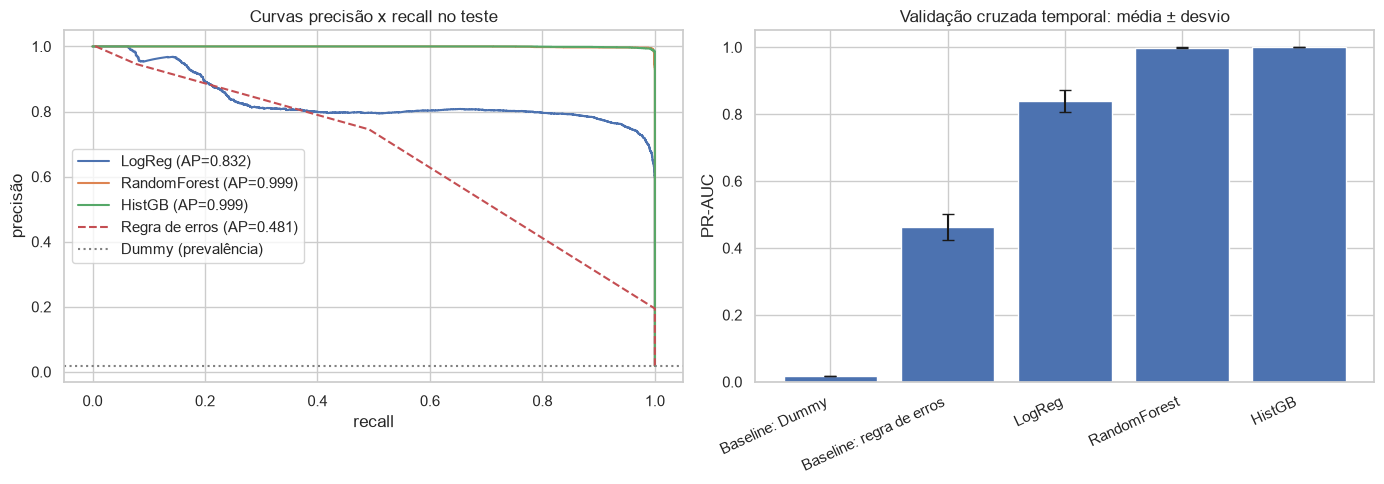

In [18]:
# Melhor modelo = maior PR-AUC médio na validação cruzada (NÃO olhamos o teste para escolher).
best_name = comparacao.loc[list(buscas)]["PR-AUC CV (média)"].idxmax()
p_best = probas_te[best_name]
thr_f1, thr_cost = limiares[best_name]
print("Melhor modelo (pela validação cruzada):", best_name)
print(f"Limiar (máx. F1): {thr_f1:.4f} | Limiar (mín. custo): {thr_cost:.4f}")

# Gráficos: (1) curvas precisão-recall no teste; (2) PR-AUC por fold, com desvio, para ver estabilidade.
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for nome, p in probas_te.items():
    prec, rec, _ = precision_recall_curve(y_te, p)
    axes[0].plot(rec, prec, label=f"{nome} (AP={average_precision_score(y_te, p):.3f})")
prec, rec, _ = precision_recall_curve(y_te, score_regra_te)
axes[0].plot(rec, prec, "--", label=f"Regra de erros (AP={average_precision_score(y_te, score_regra_te):.3f})")
axes[0].axhline(y_te.mean(), color="gray", ls=":", label="Dummy (prevalência)")
axes[0].set(xlabel="recall", ylabel="precisão", title="Curvas precisão x recall no teste"); axes[0].legend()

cv_tab = comparacao[["PR-AUC CV (média)", "PR-AUC CV (desvio)"]]
axes[1].bar(range(len(cv_tab)), cv_tab["PR-AUC CV (média)"], yerr=cv_tab["PR-AUC CV (desvio)"], capsize=4)
axes[1].set_xticks(range(len(cv_tab))); axes[1].set_xticklabels(cv_tab.index, rotation=25, ha="right")
axes[1].set(ylabel="PR-AUC", title="Validação cruzada temporal: média ± desvio")
plt.tight_layout(); plt.show()

**Como ler:**
- **Curvas precisão x recall:** quanto mais a curva se aproxima do canto superior direito, melhor. A linha pontilhada é o desempenho de um modelo aleatório.
- **Barras com desvio:** barras altas e desvios pequenos significam desempenho **estável ao longo dos meses**.
- **Se a Regressão Logística ficar abaixo das árvores** (o esperado): isso indica que a relação entre variáveis e falha é **não linear** (por exemplo, "erros altos *e* sensor alto *e* manutenção antiga" juntos), e as árvores capturam isso melhor.
- **Valores próximos de 1:** observe com desconfiança saudável. As seções 11 e 12 investigam por que o problema é "fácil" neste dataset.

## 10. Avaliação detalhada do melhor modelo no teste

Apresentamos o modelo escolhido em **dois limiares** (máximo F1 e mínimo custo), a **matriz de confusão** e uma métrica por **evento**.

**Por que a métrica por evento:** uma única falha gera cerca de 24 linhas positivas. Contando por linha, acertar muitas linhas de uma mesma falha infla os números. A pergunta que importa para a operação é: **"de cada falha real, quantas foram avisadas, e com quantas horas de antecedência?"**

- A antecedência máxima possível é 24h (a própria definição do alvo). Uma mediana de 24h indica que o alerta soa assim que a janela de risco se abre.
- **Alarmes falsos por máquina-dia:** quantas linhas de alerta indevido, em média, cada máquina gera por dia.

Modelo: HistGB
            limiar  precisão  recall      F1      TP     FP   FN        TN  custo
máx. F1     0.6269    0.9797     1.0  0.9897  4050.0   84.0  0.0  217366.0   84.0
mín. custo  0.3285    0.9752     1.0  0.9874  4050.0  103.0  0.0  217347.0  103.0


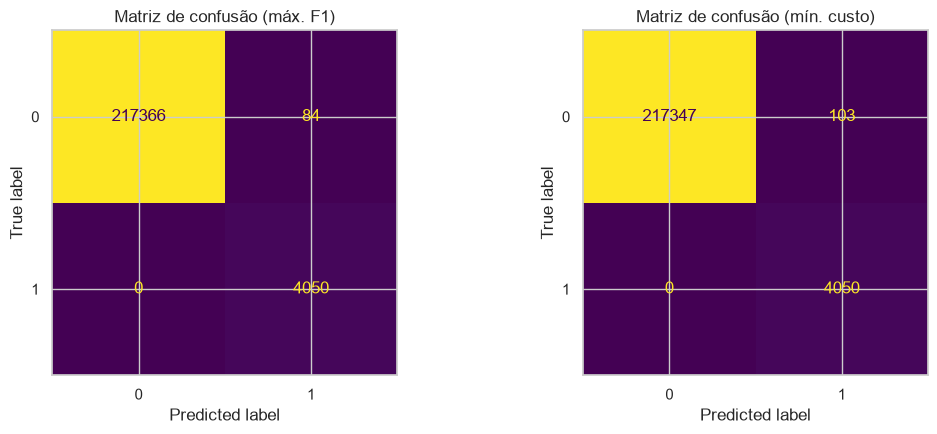

In [19]:
res = pd.DataFrame({"máx. F1": metricas_em(y_te, p_best, thr_f1),
                    "mín. custo": metricas_em(y_te, p_best, thr_cost)}).T
print(f"Modelo: {best_name}")
print(res.round(4).to_string())

# Matriz de confusão: linhas = realidade, colunas = previsão.
# Diagonal principal = acertos; fora dela: falsos positivos (alarme falso) e falsos negativos (falha não avisada).
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, thr, titulo in ((axes[0], thr_f1, "Matriz de confusão (máx. F1)"),
                        (axes[1], thr_cost, "Matriz de confusão (mín. custo)")):
    ConfusionMatrixDisplay.from_predictions(y_te, (p_best >= thr).astype(int), ax=ax, colorbar=False)
    ax.set_title(titulo)
plt.tight_layout(); plt.show()

In [20]:
def event_report(test_df, proba, thr, failures, start):
    """Para cada falha do período de teste: houve algum alerta nas 24h anteriores? Quantas horas antes soou o primeiro?"""
    t = test_df[["machineID", "datetime"]].copy()
    t["alert"] = np.asarray(proba) >= thr
    t = {k: g.set_index("datetime") for k, g in t.groupby("machineID")}
    out = []
    ev = failures[failures.datetime >= start].drop_duplicates(["machineID", "datetime"])
    for _, f in ev.iterrows():
        g = t.get(f.machineID)
        if g is None:
            continue
        # Janela relevante: de 24h antes da falha até 1h antes (linhas cujo rótulo é 1 por causa desta falha).
        w = g.loc[f.datetime - pd.Timedelta(hours=HORIZON_H): f.datetime - pd.Timedelta(hours=1)]
        if len(w) == 0:
            continue
        hits = w[w.alert]
        out.append({"machineID": f.machineID, "falha_em": f.datetime, "detectada": len(hits) > 0,
                    "antecedência_h": (f.datetime - hits.index.min()) / pd.Timedelta(hours=1) if len(hits) else np.nan})
    return pd.DataFrame(out)

n_days = (test.datetime.max() - test.datetime.min()).days + 1
for label, thr in (("máx. F1", thr_f1), ("mín. custo", thr_cost)):
    ev = event_report(test, p_best, thr, failures, TEST_START)
    fp_rows = int(((p_best >= thr) & (y_te.values == 0)).sum())
    print(f"[{label}] falhas no teste: {len(ev)} | detectadas: {int(ev.detectada.sum())} ({ev.detectada.mean():.1%}) "
          f"| antecedência mediana: {ev['antecedência_h'].median():.1f}h "
          f"| linhas de alarme falso por máquina-dia: {fp_rows / (test.machineID.nunique() * n_days):.4f}")

[máx. F1] falhas no teste: 171 | detectadas: 171 (100.0%) | antecedência mediana: 24.0h | linhas de alarme falso por máquina-dia: 0.0090
[mín. custo] falhas no teste: 171 | detectadas: 171 (100.0%) | antecedência mediana: 24.0h | linhas de alarme falso por máquina-dia: 0.0111


## 11. Experimentos de remoção de features (ablação)

**Pergunta:** *de onde vem o desempenho?* Se tirarmos um grupo de variáveis e o resultado despencar, esse grupo é o que sustenta o modelo. Se nada mudar, há redundância (outros grupos carregam o mesmo sinal).

**Como:** treinamos o Gradient Boosting (com os melhores hiperparâmetros encontrados) várias vezes, cada uma **sem** um grupo de variáveis, e avaliamos no teste.

**Por que isso importa para a análise crítica:** se o desempenho alto depender de poucos grupos que, no mundo real, seriam ruidosos ou inexistentes, o resultado é menos transferível para a prática.

> Métricas independentes de limiar (PR-AUC, ROC-AUC) são as principais. O "F1 máximo" é calculado **no próprio teste** e por isso é **otimista**; serve só para comparar os experimentos entre si.

In [21]:
# Definição dos grupos de features por prefixo do nome.
grupos = {
    "sensores": [c for c in FEATURES if c.split("_")[0] in SENSORS],
    "erros":    [c for c in FEATURES if c.startswith("error") or c.startswith("err_")],
    "manutenção": [c for c in FEATURES if c.startswith("h_since_maint")],
    "última falha": [c for c in FEATURES if c == "h_since_fail"],
    "metadados": [c for c in FEATURES if c == "age" or c.startswith("model_")],
}
# Conferência: os grupos devem cobrir TODAS as features, sem sobreposição.
assert sorted(sum(grupos.values(), [])) == sorted(FEATURES), "Grupos de features não cobrem exatamente FEATURES"
print({g: len(c) for g, c in grupos.items()})

cenarios = {
    "Todas as features": [],
    "Sem erros": ["erros"],
    "Sem manutenção": ["manutenção"],
    "Sem erros e sem manutenção": ["erros", "manutenção"],
    "Sem sensores": ["sensores"],
    "Só sensores": ["erros", "manutenção", "última falha", "metadados"],
    "Só erros": ["sensores", "manutenção", "última falha", "metadados"],
}

modelo_ablacao = clone(buscas["HistGB"].best_estimator_)      # mesmo Gradient Boosting, mesmos hiperparâmetros
linhas_abl = []
for nome_c, removidos in cenarios.items():
    t0 = time.time()
    remover = set(sum([grupos[g] for g in removidos], []))
    cols = [c for c in FEATURES if c not in remover]
    m = clone(modelo_ablacao).fit(X_dev[cols], y_dev)
    p = m.predict_proba(X_te[cols])[:, 1]
    prec, rec, _ = precision_recall_curve(y_te, p)
    f1_max = np.max(2 * prec * rec / np.clip(prec + rec, 1e-12, None))
    linhas_abl.append({"cenário": nome_c, "nº features": len(cols),
                       "PR-AUC": average_precision_score(y_te, p), "ROC-AUC": roc_auc_score(y_te, p),
                       "F1 máx. (otimista)": f1_max})
    print(f"{nome_c:28s} PR-AUC={linhas_abl[-1]['PR-AUC']:.4f}  ({time.time() - t0:.0f}s)")

ablacao = pd.DataFrame(linhas_abl).set_index("cenário")
ablacao.round(4)

{'sensores': 40, 'erros': 12, 'manutenção': 4, 'última falha': 1, 'metadados': 5}
Todas as features            PR-AUC=0.9994  (20s)
Sem erros                    PR-AUC=0.8964  (20s)
Sem manutenção               PR-AUC=0.9995  (21s)
Sem erros e sem manutenção   PR-AUC=0.7840  (19s)
Sem sensores                 PR-AUC=0.9762  (11s)
Só sensores                  PR-AUC=0.2229  (15s)
Só erros                     PR-AUC=0.7056  (7s)


,nº features,PR-AUC,ROC-AUC,F1 máx. (otimista)
cenário,,,,
Todas as features,62,0.9994,1.0000,0.9934
Sem erros,50,0.8964,0.9985,0.8845
Sem manutenção,58,0.9995,1.0000,0.9954
Sem erros e sem manutenção,46,0.7840,0.9961,0.7813
Sem sensores,22,0.9762,0.9996,0.9513
Só sensores,40,0.2229,0.9615,0.3088
Só erros,12,0.7056,0.9910,0.6895


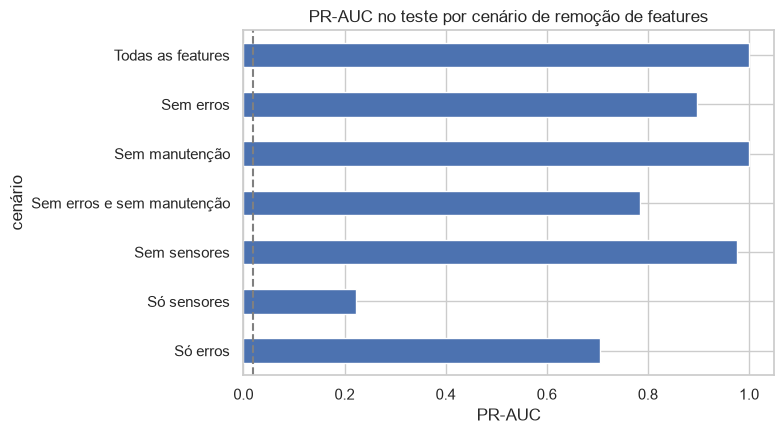

In [22]:
# Visualização: PR-AUC de cada cenário. A linha tracejada é a prevalência (modelo aleatório).
ax = ablacao["PR-AUC"].plot.barh(figsize=(8, 4.5), title="PR-AUC no teste por cenário de remoção de features")
ax.axvline(y_te.mean(), color="gray", ls="--"); ax.invert_yaxis(); ax.set_xlabel("PR-AUC")
plt.tight_layout(); plt.show()

**Como interpretar:**
- Cenários que **mantêm** PR-AUC alta sem um grupo: aquele grupo é substituível, porque o sinal está presente em outros.
- Cenário **"Só sensores"**: mostra se os sensores, sozinhos, bastam. Em dados reais, é o cenário mais honesto, porque erros e logs nem sempre existem ou são confiáveis.
- Cenário **"Só erros"**: indica o quanto o indicador "houve erros recentes" explica por si só.
- Quedas grandes ao remover um grupo indicam **dependência** do modelo em relação a ele.

**Resultado desta execução (PR-AUC no teste):**

| Cenário | PR-AUC |
|---|---|
| Todas as features | 0,999 |
| Sem manutenção | 0,999 (nenhuma queda: grupo substituível) |
| Sem sensores | 0,976 |
| Sem erros | 0,896 |
| Sem erros e sem manutenção | 0,784 |
| Só erros | 0,706 |
| Só sensores | 0,223 |

**Leitura:** o grupo **erros** é o que mais sustenta o desempenho (sozinho já chega a 0,71), enquanto os **sensores sozinhos** ficam muito abaixo (0,22), embora o ROC-AUC deles ainda seja alto (0,96). Hipótese compatível com os dados, que não foi testada diretamente: os sensores indicam que "há algo anormal" (patamar de 48h antes da falha), mas não localizam com precisão as **últimas 24h**, e os erros ajudam a marcar essa janela. A manutenção não acrescenta nada quando os demais grupos estão presentes.

## 12. Interpretação do modelo

**Importância por permutação:** embaralhamos uma variável por vez no teste e medimos quanto a PR-AUC cai. Quanto maior a queda, mais o modelo depende dela. É um método simples e vale para qualquer modelo.

**O que verificar:**
- As variáveis mais importantes fazem **sentido físico** (erros recentes, vibração, tempo desde a manutenção)?
- Uma única variável dominando tudo é sinal de que o problema é "fácil" ou de possível vazamento, e deve ser investigada.

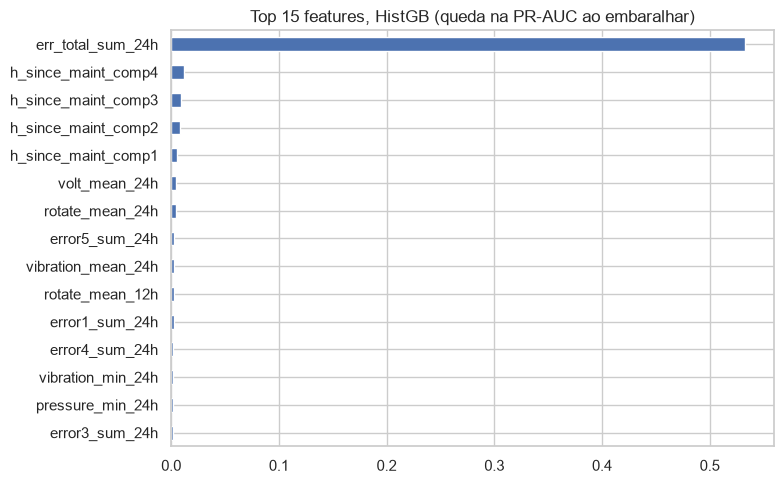

In [23]:
# Importância por permutação, em uma amostra do teste (40 mil linhas) para não demorar muito.
rng = np.random.RandomState(RANDOM_STATE)
idx = rng.choice(len(X_te), size=min(40000, len(X_te)), replace=False)
pi = permutation_importance(buscas[best_name].best_estimator_, X_te.iloc[idx], y_te.iloc[idx],
                            scoring="average_precision", n_repeats=3,
                            random_state=RANDOM_STATE, n_jobs=-1)
imp = pd.Series(pi.importances_mean, index=FEATURES).sort_values(ascending=False).head(15)
imp[::-1].plot.barh(figsize=(8, 5), title=f"Top 15 features, {best_name} (queda na PR-AUC ao embaralhar)")
plt.tight_layout(); plt.show()

In [24]:
# O desempenho é parecido entre os 4 modelos de máquina? Evita que o resultado esconda um modelo problemático.
mc = [c for c in FEATURES if c.startswith("model_")]
grp_model = test[mc].idxmax(axis=1).str.replace("model_", "")         # reconstrói "model1..model4" a partir do one-hot
rows = {}
for g in sorted(grp_model.unique()):
    mk = (grp_model == g).values
    if y_te[mk].sum() > 0:
        rows[g] = {"linhas": int(mk.sum()), "positivos": int(y_te[mk].sum()),
                   "PR-AUC": average_precision_score(y_te[mk], p_best[mk])}
pd.DataFrame(rows).T.round(4)

,linhas,positivos,PR-AUC
model1,35440.0,1014.0,0.9994
model2,37655.0,918.0,0.9980
model3,77525.0,1128.0,1.0000
model4,70880.0,990.0,0.9995


In [25]:
# Inspeção qualitativa dos erros do modelo (no limiar de máximo F1).
chk = test[["machineID", "datetime", "target"]].copy()
chk["proba"] = p_best
fn_cases = chk[(chk.target == 1) & (chk.proba < thr_f1)].sort_values("proba").head(5)
fp_cases = chk[(chk.target == 0) & (chk.proba >= thr_f1)].sort_values("proba", ascending=False).head(5)
print("Falsos negativos mais graves (falha em até 24h que o modelo NÃO avisou):\n", fn_cases.to_string(index=False))
print("\nFalsos positivos mais confiantes (alerta dado, mas sem falha nas próximas 24h):\n", fp_cases.to_string(index=False))

# Hipótese a conferir: os falsos positivos ocorrem pouco ANTES da janela de 24h (ou seja, a falha acontece logo depois)?
# Se sim, o "erro" do modelo é na verdade um alerta antecipado, e não um alarme sem fundamento.
fp_all = chk[(chk.target == 0) & (chk.proba >= thr_f1)].copy()
nxt = failures[["machineID", "datetime"]].drop_duplicates().rename(columns={"datetime": "prox_falha"}).sort_values("prox_falha")
fp_all = pd.merge_asof(fp_all.sort_values("datetime"), nxt.assign(datetime=nxt.prox_falha),
                       on="datetime", by="machineID", direction="forward", allow_exact_matches=False)
fp_all["horas_ate_falha"] = (fp_all["prox_falha"] - fp_all["datetime"]) / pd.Timedelta(hours=1)
print("\nFalsos positivos: horas até a PRÓXIMA falha real (distribuição):")
print(fp_all["horas_ate_falha"].describe().round(1).to_string())
print(f"Fração dos falsos positivos com falha real entre 24h e 72h depois: "
      f"{((fp_all.horas_ate_falha > 24) & (fp_all.horas_ate_falha <= 72)).mean():.1%}")

Falsos negativos mais graves (falha em até 24h que o modelo NÃO avisou):
 Empty DataFrame
Columns: [machineID, datetime, target, proba]
Index: []

Falsos positivos mais confiantes (alerta dado, mas sem falha nas próximas 24h):
  machineID            datetime  target  proba
        20 2015-12-14 05:00:00       0    1.0
        92 2015-10-18 11:00:00       0    1.0
        20 2015-12-14 04:00:00       0    1.0
        20 2015-12-14 03:00:00       0    1.0
        20 2015-12-14 02:00:00       0    1.0

Falsos positivos: horas até a PRÓXIMA falha real (distribuição):
count      69.0
mean      557.9
std       411.7
min        25.0
25%       181.0
50%       418.0
75%      1055.0
max      1105.0
Fração dos falsos positivos com falha real entre 24h e 72h depois: 13.1%


## 13. Conclusões, limitações e próximos passos

### Resultados desta execução (resumo para a apresentação)

| Modelo | PR-AUC CV (média ± desvio) | PR-AUC teste | Precisão | Recall | F1 |
|---|---|---|---|---|---|
| Baseline: Dummy | 0,0188 ± 0,0002 | 0,0183 | 0,018 | 0,019 | 0,018 |
| Baseline: regra de erros | 0,4638 ± 0,0387 | 0,4812 | 0,195 | 1,000 | 0,326 |
| Regressão Logística | 0,8384 ± 0,0329 | 0,8319 | 0,760 | 0,941 | 0,841 |
| Random Forest | 0,9992 ± 0,0009 | 0,9992 | 0,987 | 0,997 | 0,992 |
| **Gradient Boosting (escolhido pela CV)** | **0,9998 ± 0,0002** | **0,9994** | **0,980** | **1,000** | **0,990** |

- **Melhor modelo no teste final (Gradient Boosting, limiar de máximo F1):** 4.050 acertos, **0 falhas não avisadas** e 84 linhas de alarme falso (de ~217 mil linhas normais). Por evento: **171 de 171 falhas avisadas**, com antecedência mediana de 24h (que é o teto do desenho do problema) e cerca de 0,009 linhas de alarme falso por máquina-dia.
- **Random Forest e Gradient Boosting são praticamente empatados** (diferenças na terceira casa decimal, dentro da variação entre folds). Não há base para afirmar que um é melhor que o outro.
- **Hiperparâmetros pouco influenciam** o resultado: as combinações testadas ficam muito próximas, e na Regressão Logística o parâmetro C quase não muda nada (0,833 a 0,838). A diferença entre o modelo linear e as árvores vem da **estrutura do modelo** (relação não linear), não de ajuste fino.
- **Importância das features:** `err_total_sum_24h` domina de longe (queda de cerca de 0,53 na PR-AUC quando embaralhada); as demais têm contribuição pequena.

### Principais conclusões
1. **O pipeline é sólido e reprodutível:** dados limpos, rótulo bem definido, features só com passado, validação cronológica com embargo e teste final intocado.
2. **Todos os modelos superam os dois baselines em PR-AUC e F1**, e os de árvores o fazem com ampla folga (PR-AUC 0,999 contra 0,48 da regra simples de erros).
3. **Desempenho estável:** desvios entre os folds de julho, agosto e setembro são muito pequenos para as árvores (≤ 0,001).
4. **Árvores superam o modelo linear** (0,999 contra 0,84), o que indica relação não linear entre erros, sensores e falha.
5. **O sinal mais forte está nos erros recentes.** Sem eles o desempenho cai para 0,90; só com sensores cai para 0,22.

### Limitações (devem ser ditas na apresentação)
- **Os dados parecem simulados.** O estudo de evento (seção 2) mostra um degrau limpo e constante 48h antes de toda falha, e a regra "pelo menos 1 erro nas últimas 24h" já pega 100% das linhas pré-falha. Isso torna o problema **artificialmente fácil**; resultados próximos de 100% **não devem ser extrapolados** para operação real.
- **Falsos positivos não são, em sua maioria, "alertas antecipados".** Dos 84 falsos positivos, apenas 11 (13%) ocorrem entre 24h e 72h antes de uma falha real; 15 não têm falha posterior no período e a mediana de distância até a próxima falha é de ~418h. Há episódios de alerta com probabilidade ≈ 1,0 sem falha por perto (por exemplo, máquina 20 em 14/12/2015 e máquina 92 em 18/10/2015) que merecem investigação: podem ser anomalias que não levaram à falha neste dataset.
- **Alvo único para qualquer componente:** um modelo por componente seria mais acionável para a manutenção.
- **Janela de teste limitada:** 171 falhas; não foram calculados intervalos de confiança.
- **Limiar de custo:** o limiar de mínimo custo escolhido na validação teve custo ligeiramente maior que o de máximo F1 no teste (103 contra 84), sinal de que o limiar é sensível ao período usado para escolhê-lo.

### Próximos passos
- **Validar em dados reais** (por exemplo, o dataset MetroPT-3) para medir o desempenho sem precursores artificiais.
- Investigar os episódios de falso positivo de alta confiança.
- Testar outros horizontes (12h, 48h, 72h) e a modelagem por componente.
- Calibrar as probabilidades e ajustar `COST_FN` / `COST_FP` com custos reais de operação.
- Reportar intervalos de confiança (por exemplo, *bootstrap* por máquina).

In [26]:
# ---------------------- RESUMO AUTOMÁTICO PARA A APRESENTAÇÃO ----------------------
# Esta célula monta, com os números desta execução, as frases principais que você pode falar no vídeo.
rt = comparacao.loc[best_name]
mf = metricas_em(y_te, p_best, thr_f1)
ev_f1 = event_report(test, p_best, thr_f1, failures, TEST_START)
print(f"1) Problema: prever falha em até {HORIZON_H}h; prevalência de positivos = {y_te.mean():.2%} (classes muito desbalanceadas).")
print(f"2) Baselines: Dummy PR-AUC = {comparacao.loc['Baseline: Dummy', 'PR-AUC teste']:.3f} | "
      f"regra de erros PR-AUC = {comparacao.loc['Baseline: regra de erros', 'PR-AUC teste']:.3f}, F1 = {comparacao.loc['Baseline: regra de erros', 'F1']:.3f}.")
print(f"3) Melhor modelo na validação cruzada: {best_name} (PR-AUC médio = {rt['PR-AUC CV (média)']:.4f} ± {rt['PR-AUC CV (desvio)']:.4f}).")
print(f"4) No teste final: PR-AUC = {rt['PR-AUC teste']:.4f}, precisão = {mf['precisão']:.3f}, recall = {mf['recall']:.3f}, F1 = {mf['F1']:.3f}.")
print(f"5) Por evento: {int(ev_f1.detectada.sum())} de {len(ev_f1)} falhas avisadas; antecedência mediana = {ev_f1['antecedência_h'].median():.0f}h.")
print(f"6) Ablação: PR-AUC sem erros = {ablacao.loc['Sem erros', 'PR-AUC']:.3f} | só sensores = {ablacao.loc['Só sensores', 'PR-AUC']:.3f} | "
      f"todas = {ablacao.loc['Todas as features', 'PR-AUC']:.3f}.")
print("7) Ressalva: os dados aparentam ser simulados (degrau de 48h antes da falha), então o desempenho não deve ser extrapolado para o mundo real.")

1) Problema: prever falha em até 24h; prevalência de positivos = 1.83% (classes muito desbalanceadas).
2) Baselines: Dummy PR-AUC = 0.018 | regra de erros PR-AUC = 0.481, F1 = 0.326.
3) Melhor modelo na validação cruzada: HistGB (PR-AUC médio = 0.9998 ± 0.0002).
4) No teste final: PR-AUC = 0.9994, precisão = 0.980, recall = 1.000, F1 = 0.990.
5) Por evento: 171 de 171 falhas avisadas; antecedência mediana = 24h.
6) Ablação: PR-AUC sem erros = 0.896 | só sensores = 0.223 | todas = 0.999.
7) Ressalva: os dados aparentam ser simulados (degrau de 48h antes da falha), então o desempenho não deve ser extrapolado para o mundo real.
